<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [National Hockey League Data](https://github.com/Query-farm/vgi-nhl)

NHL standings, scores, play-by-play, and player statistics as SQL tables.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nhl/blob/main/notebooks/03_join_season_identity_before_comparing_ledgers.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nhl/blob/main/notebooks/README.md)


## Choose the season identity before comparing scoring ledgers

**Can two NHL reports agree on points while reporting different goal totals—and can today’s reference labels duplicate a historical team?** Use the completed 2024–25 regular season, anchor team IDs in that season’s report, then compare the same 32 teams.

**Real public NHL responses, recorded independently on 2026-11-15 UTC.**
The default replays unchanged response bodies through the real released worker.
These are historical observations, not a synthetic scenario or an atomic live
snapshot. The [provenance manifest](recordings/provenance.json) records exact URLs,
request parameters, acquisition times and hashes. All joins and choices remain visible SQL.

### Choose one local rule

`MIN_POINTS` is an integer 50–120, a local cohort threshold on final standings points. Change 90→100. All 32 teams remain available, while the highlighted comparison population changes.

In [1]:
DATA_MODE = "replay"
MIN_POINTS = 90

In [2]:
import importlib.metadata

try:
    _shared_version = importlib.metadata.version("vgi-example-notebooks")
except importlib.metadata.PackageNotFoundError:
    _shared_version = None
if _shared_version != "0.3.49":
    %pip -q install "vgi-example-notebooks @ git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.49"
from vgi_notebooks import check_runtime
from vgi_notebooks.bootstrap import prepare

check_runtime()
_companion_directory = prepare("nhl")

In [3]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from nhl_examples import NHLExample

if type(MIN_POINTS) is not int or not 50 <= MIN_POINTS <= 120:
    raise ValueError("MIN_POINTS must be an integer from 50 through 120")
source = NHLExample(DATA_MODE, "season")
theme()
session = connect(globals())
SOURCE = (
    "Recorded public NHL responses · captured 2026-11-15 UTC"
    if DATA_MODE == "replay"
    else "Live public NHL responses · independent endpoint reads"
) + " · worker v0.2.0"

### Attach the released worker

The public tag owns dependencies in an isolated Python 3.13 worker environment.
Shared base tooling leaves the kernel intact and starts UTC with an empty temporary
SQL-secret store and persistence disabled. The replay helper redirects all NHL roots
to loopback, verifies response hashes and rejects requests outside this scenario.
Live mode clears inherited URL overrides and never falls back to replay.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nhl' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-nhl@v0.2.0 vgi-nhl');

,Success


### Get the season window from the catalog

`standings_seasons` supplies the final standings date and the applicable rule flags.
Choose season **20242025**, then inspect its returned window. The next request uses
its recorded end date **2025-04-17** explicitly; a check ties that literal back to
the metadata. A date chosen from today's calendar would answer a different question.

In [5]:
%%sql
CREATE TABLE seasons AS SELECT * FROM nhl.main.standings_seasons;
CREATE TABLE chosen_season AS SELECT * FROM seasons WHERE season=20242025;

,Count


In [6]:
%%sql window <<
SELECT * FROM chosen_season;

In [7]:
display(window)
prose(
    f"Season **{int(window.season.iloc[0])}** closes its returned standings window on "
    f"**{window.standings_end.iloc[0]}**. The metadata records an overtime-loss point and no ties; "
    "these flags bound the points-accounting check below."
)

,season,standings_start,standings_end,conferences_in_use,divisions_in_use,point_for_ot_loss_in_use,regulation_wins_in_use,row_in_use,ties_in_use,wildcard_in_use
0,20242025,2024-10-04,2025-04-17,True,True,True,True,True,False,True


Season **20242025** closes its returned standings window on **2025-04-17 00:00:00**. The metadata records an overtime-loss point and no ties; these flags bound the points-accounting check below.

### Anchor references in the season’s team IDs

`team_stats` is one team-season row and contains a stable team ID for that report.
Join `teams` on that ID, then join dated `standings` on the resulting code. Do not
start by joining the historical code to every reference row: the reference catalog
retains multiple identities for some codes. `franchises` supplies the most recent
franchise label, which is useful context but is not necessarily the historical name.

In [8]:
%%sql
CREATE TABLE final_standings AS SELECT * FROM nhl.main.standings(date:=DATE '2025-04-17');
CREATE TABLE season_stats AS SELECT * FROM nhl.main.team_stats(season:=20242025);
CREATE TABLE team_reference AS SELECT * FROM nhl.main.teams;
CREATE TABLE franchise_reference AS SELECT * FROM nhl.main.franchises;
CREATE TABLE aligned AS
SELECT s.team_id,t.franchise_id,t.tricode,s.team_name AS season_name,
 t.full_name AS team_reference_name,f.full_name AS current_franchise_name,
 d.standings_date,d.season,d.games_played,d.points,s.points AS report_points,
 d.wins,d.ot_losses,d.league_rank,d.goals_for AS standings_goals_for,
 d.goals_against AS standings_goals_against,s.goals_for AS report_goals_for,
 s.goals_against AS report_goals_against,d.shootout_wins,d.shootout_losses
FROM season_stats s JOIN team_reference t USING(team_id)
JOIN final_standings d ON d.team_abbrev=t.tricode AND d.season=s.season
JOIN franchise_reference f USING(franchise_id);

,Count


In [9]:
%%sql identity <<
SELECT d.team_abbrev,d.team_name AS dated_name,t.team_id,t.franchise_id,t.full_name AS reference_name,
 f.full_name AS current_franchise_name,s.team_id IS NOT NULL AS in_selected_season
FROM final_standings d JOIN team_reference t ON d.team_abbrev=t.tricode
JOIN franchise_reference f USING(franchise_id) LEFT JOIN season_stats s ON s.team_id=t.team_id
WHERE d.team_abbrev IN(SELECT tricode FROM team_reference GROUP BY tricode HAVING count(*)>1)
ORDER BY d.team_abbrev,t.team_id;

In [10]:
display(identity)
prose(
    f"The ambiguous-code check returns **{len(identity)} candidate identities**. "
    "Utah Hockey Club and Utah Mammoth share UTA and franchise 40, but only team ID 59 is in "
    "the selected season report. The franchise's most recent name does not rewrite the historical row. "
    "Anchoring on the season's team ID prevents duplicating Utah before comparing statistics."
)

,team_abbrev,dated_name,team_id,franchise_id,reference_name,current_franchise_name,in_selected_season
0,UTA,Utah Hockey Club,59,40,Utah Hockey Club,Utah Mammoth,True
1,UTA,Utah Hockey Club,68,40,Utah Mammoth,Utah Mammoth,False


The ambiguous-code check returns **2 candidate identities**. Utah Hockey Club and Utah Mammoth share UTA and franchise 40, but only team ID 59 is in the selected season report. The franchise's most recent name does not rewrite the historical row. Anchoring on the season's team ID prevents duplicating Utah before comparing statistics.

### Compare quantities before assuming identical definitions

The two sources agree on standings points, but their goal totals differ. Compute
both residuals explicitly. In this captured season, each team's goals-for residual
equals its reported shootout wins, and the goals-against residual equals shootout
losses. The SQL verifies this empirical reconciliation for all 32 rows; it does not
silently overwrite either source or assume that every historical season behaves alike.

In [11]:
%%sql ledger <<
SELECT *,standings_goals_for-report_goals_for AS for_delta,
 standings_goals_against-report_goals_against AS against_delta,
 points>={{MIN_POINTS}} AS selected FROM aligned ORDER BY points DESC,tricode;

,team_id,franchise_id,tricode,season_name,team_reference_name,current_franchise_name,standings_date,season,games_played,points,...,league_rank,standings_goals_for,standings_goals_against,report_goals_for,report_goals_against,shootout_wins,shootout_losses,for_delta,against_delta,selected
0,52,35,WPG,Winnipeg Jets,Winnipeg Jets,Winnipeg Jets,2025-04-17,20242025,82,116,...,1,277,191,275,190,2,1,2,1,True
1,15,24,WSH,Washington Capitals,Washington Capitals,Washington Capitals,2025-04-17,20242025,82,111,...,2,288,232,286,229,2,3,2,3,True
2,54,38,VGK,Vegas Golden Knights,Vegas Golden Knights,Vegas Golden Knights,2025-04-17,20242025,82,110,...,3,275,219,274,214,1,5,1,5,True
3,10,5,TOR,Toronto Maple Leafs,Toronto Maple Leafs,Toronto Maple Leafs,2025-04-17,20242025,82,108,...,4,268,231,267,229,1,2,1,2,True
4,25,15,DAL,Dallas Stars,Dallas Stars,Dallas Stars,2025-04-17,20242025,82,106,...,5,277,224,275,222,2,2,2,2,True
5,26,14,LAK,Los Angeles Kings,Los Angeles Kings,Los Angeles Kings,2025-04-17,20242025,82,105,...,6,250,206,249,203,1,3,1,3,True
6,21,27,COL,Colorado Avalanche,Colorado Avalanche,Colorado Avalanche,2025-04-17,20242025,82,102,...,8,277,234,273,231,4,3,4,3,True
7,14,31,TBL,Tampa Bay Lightning,Tampa Bay Lightning,Tampa Bay Lightning,2025-04-17,20242025,82,102,...,7,294,219,292,216,2,3,2,3,True
8,22,25,EDM,Edmonton Oilers,Edmonton Oilers,Edmonton Oilers,2025-04-17,20242025,82,101,...,9,259,236,259,235,0,1,0,1,True
9,12,26,CAR,Carolina Hurricanes,Carolina Hurricanes,Carolina Hurricanes,2025-04-17,20242025,82,99,...,10,266,233,266,230,0,3,0,3,True


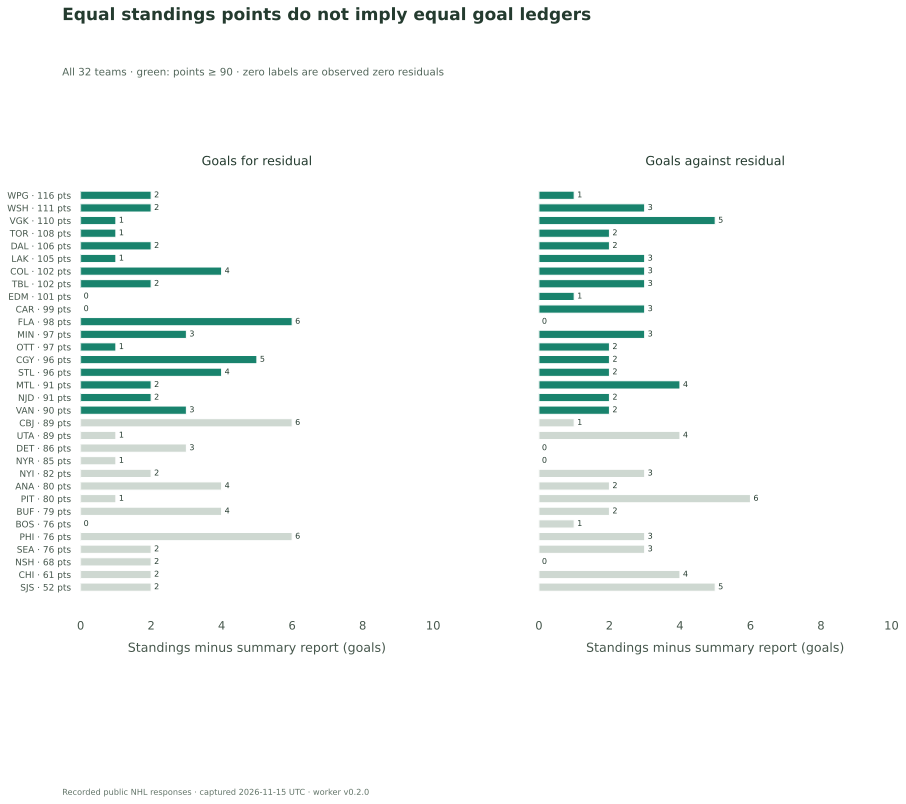

Both point columns agree for **32 teams**. Across the full league the goals-for and goals-against residuals each sum to **77**. Each row reconciles to its own reported shootout wins/losses; totals alone would not establish that.

In [12]:
display(ledger)
fig, axes = plt.subplots(1, 2, figsize=(12.8, 12.0), sharey=True)
y = np.arange(len(ledger))
colors = ["#19836D" if x else "#CED8D1" for x in ledger.selected]
for ax, key, title in zip(
    axes, ["for_delta", "against_delta"], ["Goals for residual", "Goals against residual"], strict=True
):
    bars = ax.barh(y, ledger[key], height=0.65, color=colors)
    ax.bar_label(bars, padding=3, fmt="%g", fontsize=8)
    ax.set_title(title)
    ax.set_xlim(0, 10)
    ax.set_xticks(range(0, 11, 2))
    ax.set_xlabel("Standings minus summary report (goals)")
axes[0].set_yticks(y, [f"{r.tricode} · {r.points} pts" for r in ledger.itertuples()], fontsize=9)
axes[0].invert_yaxis()
finish(
    fig,
    "Equal standings points do not imply equal goal ledgers",
    f"All {len(ledger)} teams · green: points ≥ {MIN_POINTS} · zero labels are observed zero residuals",
    SOURCE,
    name=f"goal-ledger-residuals-{MIN_POINTS}",
)
prose(
    f"Both point columns agree for **{len(ledger)} teams**. Across the full league the goals-for "
    f"and goals-against residuals each sum to **{int(ledger.for_delta.sum())}**. "
    "Each row reconciles to its own reported shootout wins/losses; totals alone would not establish that."
)

In [13]:
%%sql population <<
SELECT floor(points/10)::INTEGER*10 AS lower_points,count(*) AS teams,
 count(*) FILTER(WHERE points>={{MIN_POINTS}}) AS selected_teams
FROM aligned GROUP BY lower_points ORDER BY lower_points;

,lower_points,teams,selected_teams
0,50,1,0
1,60,2,0
2,70,4,0
3,80,7,0
4,90,9,9
5,100,6,6
6,110,3,3


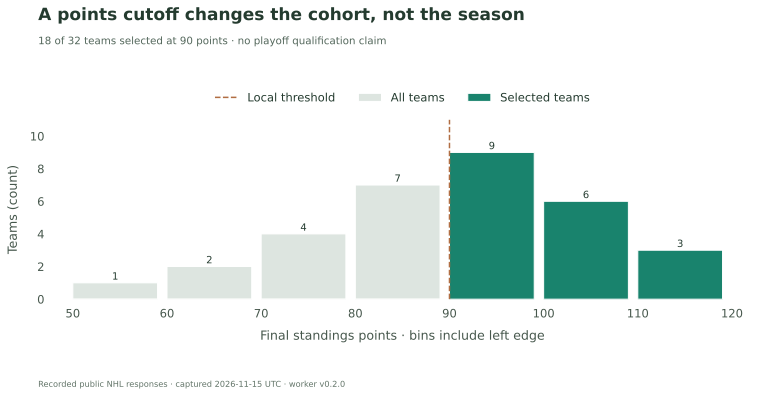

The local threshold selects **18 of 32 teams**. It is not the NHL playoff selection rule, which also depends on conference and division structure.

In [14]:
display(population)
fig, ax = plt.subplots(figsize=(11, 5.8))
ax.bar(population.lower_points, population.teams, width=9, align="edge", color="#DDE5E0", label="All teams")
ax.bar(
    population.lower_points, population.selected_teams, width=9, align="edge", color="#19836D", label="Selected teams"
)
for row in population.itertuples():
    ax.text(row.lower_points + 4.5, row.teams + 0.2, str(row.teams), ha="center", fontsize=10)
ax.axvline(MIN_POINTS, color="#B16E43", linestyle="--", label="Local threshold")
ax.set_xlim(48, 122)
ax.set_ylim(0, 11)
ax.set_yticks(range(0, 12, 2))
ax.set_xticks(range(50, 121, 10))
ax.set_xlabel("Final standings points · bins include left edge")
ax.set_ylabel("Teams (count)")
fig.legend(*ax.get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.53, 0.79), ncol=3)
finish(
    fig,
    "A points cutoff changes the cohort, not the season",
    f"{int(ledger.selected.sum())} of {len(ledger)} teams selected at {MIN_POINTS} points · no playoff qualification claim",
    SOURCE,
    name=f"season-cohort-{MIN_POINTS}",
)
prose(
    f"The local threshold selects **{int(ledger.selected.sum())} of {len(ledger)} teams**. "
    "It is not the NHL playoff selection rule, which also depends on conference and division structure."
)

In [15]:
%%sql checks <<
SELECT 'one selected season and exact end date' check_name,count(*)=1 AND min(standings_end)=DATE '2025-04-17' passed FROM chosen_season
UNION ALL SELECT 'complete 32-team alignment',count(*)=32 AND count(DISTINCT team_id)=32 AND count(DISTINCT tricode)=32 FROM aligned
UNION ALL SELECT 'unsafe code join duplicates a team',count(*)>(SELECT count(*) FROM final_standings) FROM final_standings d JOIN team_reference t ON d.team_abbrev=t.tricode
UNION ALL SELECT 'all reports retain season',bool_and(season=20242025 AND standings_date=DATE '2025-04-17') FROM aligned
UNION ALL SELECT 'point totals agree',bool_and(points=report_points) FROM aligned
UNION ALL SELECT 'modern points accounting',bool_and(points=2*wins+ot_losses) FROM aligned
UNION ALL SELECT '82-game completed season',bool_and(games_played=82) FROM aligned
UNION ALL SELECT 'goals-for residual equals shootout wins',bool_and(standings_goals_for-report_goals_for=shootout_wins) FROM aligned
UNION ALL SELECT 'goals-against residual equals shootout losses',bool_and(standings_goals_against-report_goals_against=shootout_losses) FROM aligned
UNION ALL SELECT 'league residuals balance',sum(standings_goals_for-report_goals_for)=sum(standings_goals_against-report_goals_against) FROM aligned;

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** " + source.audit())
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-03.json").write_text(
    json.dumps(
        {
            "parameters": {"MIN_POINTS": MIN_POINTS, "DATA_MODE": DATA_MODE},
            "window": window.to_dict("records"),
            "identity": identity.to_dict("records"),
            "ledger": ledger.to_dict("records"),
            "population": population.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": source.requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,one selected season and exact end date,True
1,complete 32-team alignment,True
2,unsafe code join duplicates a team,True
3,all reports retain season,True
4,point totals agree,True
5,modern points accounting,True
6,82-game completed season,True
7,goals-for residual equals shootout wins,True
8,goals-against residual equals shootout losses,True
9,league residuals balance,True


**All 10 SQL checks passed.** Exactly 5 recorded HTTP responses requested once each; no unexpected requests.

25130

### Change one thing

Change **MIN_POINTS 90→100**. Fewer teams qualify and the green highlights change. All 32 team identities, dates, points and goal residuals must remain identical; neither the historical Utah identity nor the source definitions change.

In [17]:
assert not con.execute("SELECT * FROM duckdb_secrets()").fetchall()
session.close()
source.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nhl](https://github.com/Query-farm/vgi-nhl)